# Abalone Age Prediction

The age of an abalone (a sea snail) is normally found by cutting the shell and counting rings under a microscope — slow and destructive. Predict the **ring count** (age ≈ rings + 1.5 years) from simple physical measurements instead.


In [1]:
import io, urllib.request, zipfile, gzip
import numpy as np
import pandas as pd

def download(url):
    req = urllib.request.Request(url, headers={'User-Agent': 'Mozilla/5.0'})
    with urllib.request.urlopen(req, timeout=180) as r:
        return r.read()
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import r2_score, mean_absolute_error

raw = download('https://archive.ics.uci.edu/static/public/1/abalone.zip')
zf = zipfile.ZipFile(io.BytesIO(raw))
name = [n for n in zf.namelist() if n.endswith('.data')][0]
cols = ['sex', 'length', 'diameter', 'height', 'whole_weight', 'shucked_weight', 'viscera_weight', 'shell_weight', 'rings']
df = pd.read_csv(io.BytesIO(zf.read(name)), header=None, names=cols)
print(df.shape)
df.head()

(4177, 9)


,sex,length,diameter,height,whole_weight,shucked_weight,viscera_weight,shell_weight,rings
0,M,0.455,0.365,0.095,0.5140,0.2245,0.1010,0.150,15
1,M,0.350,0.265,0.090,0.2255,0.0995,0.0485,0.070,7
2,F,0.530,0.420,0.135,0.6770,0.2565,0.1415,0.210,9
3,M,0.440,0.365,0.125,0.5160,0.2155,0.1140,0.155,10
4,I,0.330,0.255,0.080,0.2050,0.0895,0.0395,0.055,7


In [2]:
X = pd.get_dummies(df.drop(columns=['rings']), columns=['sex'], drop_first=True)
y = df['rings']
Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.25, random_state=42)
rf = RandomForestRegressor(n_estimators=300, random_state=42, n_jobs=-1).fit(Xtr, ytr)
lin = make_pipeline(StandardScaler(), LinearRegression()).fit(Xtr, ytr)
for name_m, m in [('Random Forest', rf), ('Linear', lin)]:
    p = m.predict(Xte)
    print(f'{name_m:15s} R2 {r2_score(yte, p):.3f}  MAE {mean_absolute_error(yte, p):.2f} rings')

Random Forest   R2 0.537  MAE 1.55 rings
Linear          R2 0.545  MAE 1.57 rings


shell_weight      0.497109
shucked_weight    0.168918
whole_weight      0.081371
viscera_weight    0.066233
diameter          0.055984
height            0.054961
length            0.048401
sex_I             0.019590
sex_M             0.007433
dtype: float64


<Axes: title={'center': 'What predicts abalone age?'}>

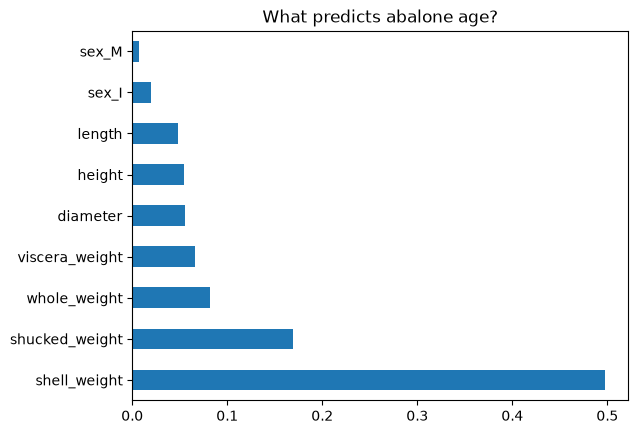

In [3]:
imp = pd.Series(rf.feature_importances_, index=X.columns).sort_values(ascending=False)
print(imp)
imp.plot(kind='barh', title='What predicts abalone age?')